In [16]:
import gdown
from pathlib import Path

DATA_ROOT = Path("/data/datasets/")
SONAR_MAST3R_ROOT = DATA_ROOT / "sonar-mast3r"

SONAR_MAST3R_ROOT.mkdir(parents=True, exist_ok=True)

# DOWNLOAD SONAR-MAST3R DATASET (only prepared version)
if not any(SONAR_MAST3R_ROOT.iterdir()):
    gdown.download_folder(
        "https://drive.google.com/drive/folders/1JZJ7mVTBFKso9r6pMpeQnXX-aZOTD72T",
        output=str(SONAR_MAST3R_ROOT), quiet=False,
    )




In [3]:
# list all files in the dataset1 folder
for file in (SONAR_MAST3R_ROOT / "dataset1").iterdir():
    print(file)

/data/datasets/sonar-mast3r/dataset1/poses_tf.pkl
/data/datasets/sonar-mast3r/dataset1/voxel_grid_smoothed.obj
/data/datasets/sonar-mast3r/dataset1/voxel_grid_meshed.obj
/data/datasets/sonar-mast3r/dataset1/cam_frames
/data/datasets/sonar-mast3r/dataset1/voxel_grid_tensor.pt
/data/datasets/sonar-mast3r/dataset1/sonar_frames
/data/datasets/sonar-mast3r/dataset1/camera.mp4
/data/datasets/sonar-mast3r/dataset1/sonar.mp4
/data/datasets/sonar-mast3r/dataset1/keyframes.pt


In [ ]:
# split camera.mp4 and sonar.mp4 into frames and save them in the dataset1 folder




## Dataset 1: frames and poses from the ROS bag

Only `dataset1` is used. Frames and poses come from the authors' ROS bag (project-page Drive, `08SEP25 - bagfiles`) rather than the processed videos: uncompressed images, all 1119 sonar frames (10 Hz; the camera runs at 5 Hz) and poses stamped at each image's acquisition time. The processed `poses_tf.pkl` pairs camera frame *i* with sonar frame 2*i*+1, except in frames 485, 519 and 545 where it picked a sample about 85 ms off (the 2 to 2.5 cm sonar pose spikes). Sonar poses here are `/oculus_tf` at each sonar frame's own stamp.

In [18]:
# Export dataset1 from the authors' ROS bag (project-page Drive, "08SEP25 - bagfiles") instead of the processed videos:
# the bag has the camera (5 Hz) and sonar fan images (10 Hz) uncompressed, all 1119 sonar frames (sonar.mp4 kept every
# other one), and the sensor poses stamped at each image's own time. The bag has no raw polar pings: the sonar topic is
# already the rendered fan (722x398), so fan -> polar is still needed later.
#   /dwe_cam/image_raw                  camera, bgr8 1600x1200, 5 Hz
#   /oculus_wrist/oculus_viewer/image   sonar fan, bgr8 722x398, 10 Hz
#   /dwe_tf, /oculus_tf                 world -> dwe_cam / oculus_link (forward kinematics), stamped like the images
# Images and poses are paired by header stamp (acquisition time), not by message order.
# Output: dataset1_bag/{cam_frames, sonar_frames}/frame_000000.png ... (in stamp order) and poses.npz.
import cv2
import numpy as np
from rosbags.rosbag1 import Reader

import opti

BAG = SONAR_MAST3R_ROOT / "bagfiles/dataset1_2025-09-08-16-44-04.bag"
SEQ = SONAR_MAST3R_ROOT / "dataset1_bag"
IMAGE_TOPICS = {"cam": "dwe_cam/image_raw", "sonar": "oculus_wrist/oculus_viewer/image"}
POSE_TOPICS = {"cam": "dwe_tf", "sonar": "oculus_tf"}

def export_bag(bag: Path, out: Path):
    """One pass over the bag: write every image as PNG, collect image stamps and pose stamps/transforms."""
    ts = opti.make_typestore(bag)
    topic_key = {t: ("image", k) for k, t in IMAGE_TOPICS.items()} | {t: ("pose", k) for k, t in POSE_TOPICS.items()}
    images = {k: [] for k in IMAGE_TOPICS}                     # (stamp, temp path)
    poses = {k: [] for k in POSE_TOPICS}                       # (stamp, x, y, z, qx, qy, qz, qw)
    for k in IMAGE_TOPICS:
        (out / f"{k}_frames").mkdir(parents=True, exist_ok=True)
    with Reader(bag) as r:
        conns = [c for c in r.connections if opti._norm(c.topic) in topic_key]
        for conn, _, raw in r.messages(connections=conns):
            kind, k = topic_key[opti._norm(conn.topic)]
            m = ts.deserialize_ros1(raw, conn.msgtype)
            if kind == "image":
                assert m.encoding == "bgr8" and m.step == 3 * m.width
                tmp = out / f"{k}_frames/tmp_{len(images[k]):06d}.png"
                cv2.imwrite(str(tmp), np.frombuffer(m.data, np.uint8).reshape(m.height, m.width, 3))
                images[k].append((opti.stamp_ns(m), tmp))
            else:
                tr, q = m.transform.translation, m.transform.rotation   # ROS quaternion fields: x, y, z, w
                poses[k].append((opti.stamp_ns(m), tr.x, tr.y, tr.z, q.x, q.y, q.z, q.w))
    arrays = {}
    for k in IMAGE_TOPICS:
        imgs = sorted(images[k], key=lambda s: s[0])
        for i, (_, tmp) in enumerate(imgs):                        # rename to stamp order
            tmp.rename(out / f"{k}_frames/frame_{i:06d}.png")
        stamps = np.array([s for s, _ in imgs], np.int64)
        p = np.array(sorted(poses[k]), dtype=np.float64)
        p_stamps = np.array(sorted(s for s, *_ in poses[k]), np.int64)
        # pose for each image: the pose with the same stamp (equal up to float rounding of the stamp, < 1 ms)
        j = np.clip(np.searchsorted(p_stamps, stamps), 1, len(p_stamps) - 1)
        j = np.where(np.abs(p_stamps[j] - stamps) < np.abs(p_stamps[j - 1] - stamps), j, j - 1)
        gap = np.abs(p_stamps[j] - stamps)
        assert gap.max() < 1_000_000, f"{k}: image without a pose within 1 ms (max gap {gap.max() / 1e6:.1f} ms)"
        arrays |= {f"{k}_stamp_ns": stamps, f"{k}_pos": p[j, 1:4], f"{k}_quat": p[j, 4:8]}
    np.savez(out / "poses.npz", **arrays)

if not (SEQ / "poses.npz").exists():
    export_bag(BAG, SEQ)

In [10]:
# Load what the export wrote. Positions in metres in the arm base frame ("world"), quaternions xyzw (from the ROS field
# names, so no longer an assumption). Time t = seconds since the first camera frame.
P_ = np.load(SEQ / "poses.npz")
cam_pos, cam_quat, son_pos, son_quat = P_["cam_pos"], P_["cam_quat"], P_["sonar_pos"], P_["sonar_quat"]
T0 = P_["cam_stamp_ns"][0]
cam_t, son_t = (P_["cam_stamp_ns"] - T0) / 1e9, (P_["sonar_stamp_ns"] - T0) / 1e9
N_CAM, N_SON = len(cam_t), len(son_t)
assert len(list((SEQ / "cam_frames").glob("frame_*.png"))) == N_CAM
assert len(list((SEQ / "sonar_frames").glob("frame_*.png"))) == N_SON

# nearest sonar frame for each camera frame, and how far apart they are in time
k = np.clip(np.searchsorted(son_t, cam_t), 1, N_SON - 1)
cam_to_son = np.where(np.abs(son_t[k] - cam_t) < np.abs(son_t[k - 1] - cam_t), k, k - 1)
dt_ms = 1e3 * np.abs(son_t[cam_to_son] - cam_t)
print(f"camera: {N_CAM} frames, {cam_t[-1]:.1f} s, {1 / np.median(np.diff(cam_t)):.1f} Hz")
print(f"sonar:  {N_SON} frames, {son_t[0]:.2f} .. {son_t[-1]:.1f} s, {1 / np.median(np.diff(son_t)):.1f} Hz")
print(f"camera -> nearest sonar frame: median {np.median(dt_ms):.1f} ms, max {dt_ms.max():.1f} ms apart")
print(f"camera xyz range [m]: {cam_pos.min(0).round(3)} .. {cam_pos.max(0).round(3)}")

camera: 559 frames, 111.6 s, 5.0 Hz
sonar:  1119 frames, -0.12 .. 111.7 s, 10.0 Hz
camera -> nearest sonar frame: median 8.7 ms, max 18.5 ms apart
camera xyz range [m]: [-0.012 -0.594  0.303] .. [0.598 0.594 0.42 ]


In [11]:
# Rectify the camera frames to an ideal pinhole camera (3DGS / Z-Splat assume pinhole). camera.yaml is a ROS
# camera_calibration result: K + plumb_bob D describe the raw, distorted camera (k1 = -0.31, strong barrel
# distortion: raw corners are ~250 px off), P is the pinhole camera after rectification. Remapping K, D -> P is what
# ROS image_proc does, so this should match the authors' camera_rect.mp4 of the other datasets (dataset1 has none).
# Not known: whether the calibration was done underwater (in air would make K wrong for these images).
import yaml

calib = yaml.safe_load((SONAR_MAST3R_ROOT / "camera.yaml").read_text())
W, H = calib["image_width"], calib["image_height"]
K = np.array(calib["camera_matrix"]["data"]).reshape(3, 3)
D = np.array(calib["distortion_coefficients"]["data"])
P = np.array(calib["projection_matrix"]["data"]).reshape(3, 4)[:, :3]   # rectified intrinsics (no stereo baseline)
assert calib["distortion_model"] == "plumb_bob" and np.allclose(calib["rectification_matrix"]["data"], np.eye(3).ravel())

map_x, map_y = cv2.initUndistortRectifyMap(K, D, np.eye(3), P, (W, H), cv2.CV_32FC1)
RECT_DIR = SEQ / "cam_frames_rect"
RECT_DIR.mkdir(exist_ok=True)
for i in range(N_CAM):
    out = RECT_DIR / f"frame_{i:06d}.png"
    if not out.exists():
        cv2.imwrite(str(out), cv2.remap(cv2.imread(str(SEQ / f"cam_frames/frame_{i:06d}.png")), map_x, map_y,
                                        cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT))
print(f"{N_CAM} rectified frames in {RECT_DIR.name}/, pinhole intrinsics fx {P[0, 0]:.1f}, fy {P[1, 1]:.1f}, "
      f"cx {P[0, 2]:.1f}, cy {P[1, 2]:.1f} ({W}x{H})")

559 rectified frames in cam_frames_rect/, pinhole intrinsics fx 961.9, fy 1038.4, cx 788.8, cy 691.5 (1600x1200)


In [12]:
# Rerun: camera (blue) and sonar (orange) trajectories in the arm base frame, and the current pose of each as an axis
# triad (RGB = xyz, 5 cm), next to the rectified camera image and the sonar fan. One "time" timeline (seconds since the
# first camera frame): the camera updates at 5 Hz, the sonar at 10 Hz, each at its own stamp.
# Axes: camera +z = viewing direction, sonar +x = boresight (they are 30 deg apart, as in the paper's Fig. 3).
import rerun as rr
import rerun.blueprint as rrb

import viz

def log_dataset(rec: rr.RecordingStream, image_width: int = 800):
    rec.log("world", rr.ViewCoordinates.RIGHT_HAND_Z_UP, static=True)   # assumed: arm base frame has z up
    rec.log("world/base", rr.TransformAxes3D(0.1), static=True)
    rec.log("world/camera_path", rr.LineStrips3D([cam_pos], colors=viz.CAMERA_COLOR, radii=-1.5), static=True)
    rec.log("world/sonar_path", rr.LineStrips3D([son_pos], colors=viz.SONAR_COLOR, radii=-1.5), static=True)
    for i in range(N_CAM):
        rec.set_time("time", duration=cam_t[i])
        rec.log("world/camera", rr.Transform3D(translation=cam_pos[i], quaternion=rr.Quaternion(xyzw=cam_quat[i])),
                rr.TransformAxes3D(0.05))
        rec.log("camera", rr.EncodedImage(contents=viz._jpeg(SEQ / f"cam_frames_rect/frame_{i:06d}.png", image_width),
                                          media_type="image/jpeg"))
    for i in range(N_SON):
        rec.set_time("time", duration=son_t[i])
        rec.log("world/sonar", rr.Transform3D(translation=son_pos[i], quaternion=rr.Quaternion(xyzw=son_quat[i])),
                rr.TransformAxes3D(0.05))
        rec.log("sonar", rr.EncodedImage(path=SEQ / f"sonar_frames/frame_{i:06d}.png"))

BLUEPRINT = rrb.Blueprint(
    rrb.Horizontal(rrb.Spatial3DView(origin="world", name="poses (arm base frame)"),
                   rrb.Vertical(rrb.Spatial2DView(origin="camera"), rrb.Spatial2DView(origin="sonar")),
                   column_shares=[3, 2]),
    rrb.TimePanel(state="expanded"), collapse_panels=True)

rec = rr.RecordingStream("camera-sonar-3dgs", recording_id="sonar_mast3r_dataset1")
RRD = Path("prepared/rerun/sonar_mast3r_dataset1.rrd")
RRD.parent.mkdir(parents=True, exist_ok=True)
rec.save(RRD, default_blueprint=BLUEPRINT)
log_dataset(rec)
rec.flush()
print(f"saved {RRD} ({RRD.stat().st_size / 1e6:.0f} MB), open with: rerun {RRD}")

saved prepared/rerun/sonar_mast3r_dataset1.rrd (385 MB), open with: rerun prepared/rerun/sonar_mast3r_dataset1.rrd


In [7]:
# Inline viewer (re-logs the same data into the notebook; the .rrd above is for the standalone viewer)
rec = rr.RecordingStream("camera-sonar-3dgs", recording_id="sonar_mast3r_dataset1")
rr.notebook_show(recording=rec, blueprint=BLUEPRINT, width=1400, height=800)
log_dataset(rec)

HTML(value='<div id="b57fa7a2-602d-4016-ac98-dfbf3ccc8546"><style onload="eval(atob(\'KGFzeW5jIGZ1bmN0aW9uICgp…

## Sonar: fan -> polar

The bag has only the viewer's fan image, so the polar (range x bearing) image that `export.py` and Z-Splat expect is resampled from it (`sonar_mast3r.py`, which documents the measured fan geometry and the assumptions).

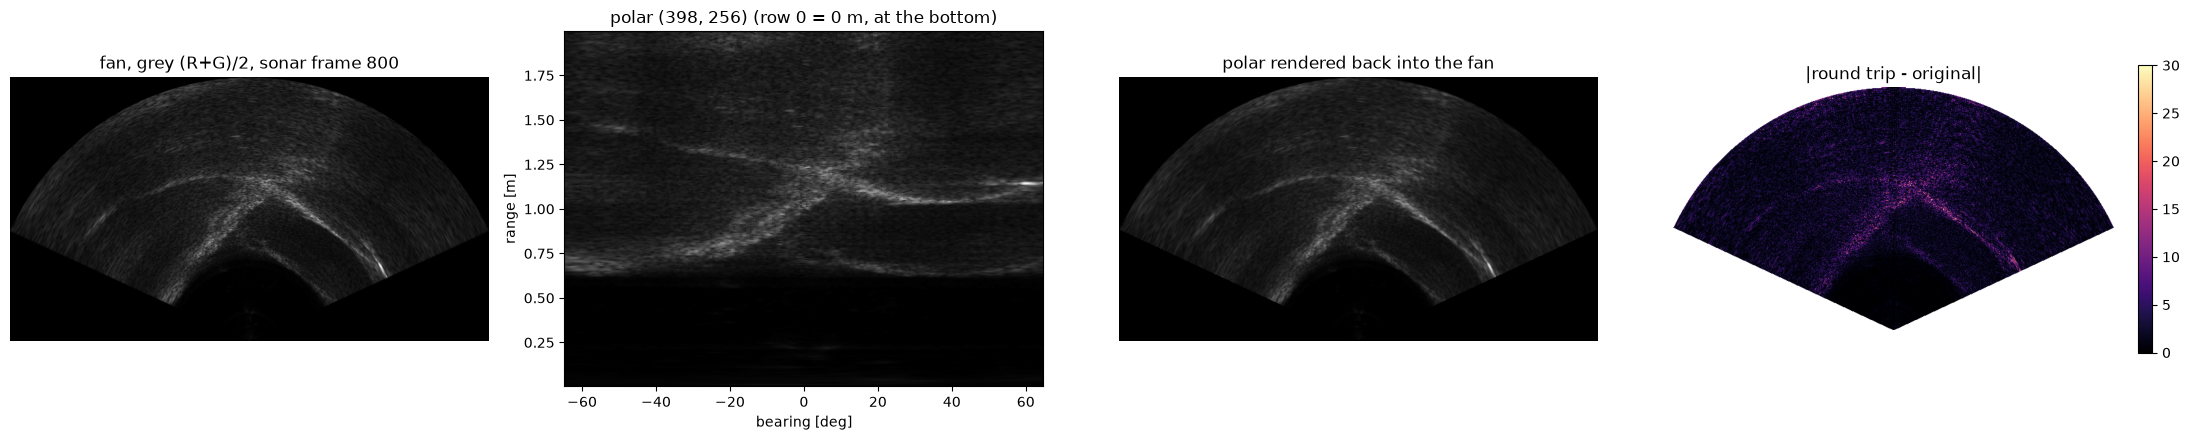

0.0-0.3 m: mean |round trip - original|  0.3 grey levels (mean level   2.2)
0.3-0.6 m: mean |round trip - original|  0.8 grey levels (mean level   9.8)
0.6-1.1 m: mean |round trip - original|  2.5 grey levels (mean level  34.4)
1.1-1.5 m: mean |round trip - original|  2.4 grey levels (mean level  33.3)
1.5-2.0 m: mean |round trip - original|  2.5 grey levels (mean level  33.3)


In [13]:
# Fan -> polar (sonar_mast3r.py): resample the viewer's fan image onto 398 ranges (0-2 m, 5 mm) x 256 bearings
# (-65..65 deg, 0.51 deg). Round trip check: render the polar image back into a fan and compare with the original
# grey values. Inside ~1.1 m the polar grid is finer than the fan (the round trip should be near-exact); further out
# 256 beams are coarser than the fan's pixels, so fine detail along the arcs is smoothed (expected, by design).
import matplotlib.pyplot as plt

import sonar_mast3r as sm

ranges, bearings = sm.polar_axes()
SHOW_SONAR = 800
fan = cv2.imread(str(SEQ / f"sonar_frames/frame_{SHOW_SONAR:06d}.png"))
polar = sm.fan_to_polar(fan)
back, inside = sm.polar_to_fan(polar)
gray = sm.fan_gray(fan)

fig, ax = plt.subplots(1, 4, figsize=(22, 4.5))
ax[0].imshow(gray, cmap="gray", vmin=0, vmax=255); ax[0].set_title(f"fan, grey (R+G)/2, sonar frame {SHOW_SONAR}")
ax[1].imshow(polar, cmap="gray", vmin=0, vmax=255, origin="lower", aspect="auto",
             extent=[np.degrees(bearings[0]), np.degrees(bearings[-1]), ranges[0], ranges[-1]])
ax[1].set(title=f"polar {polar.shape} (row 0 = 0 m, at the bottom)", xlabel="bearing [deg]", ylabel="range [m]")
ax[2].imshow(back, cmap="gray", vmin=0, vmax=255); ax[2].set_title("polar rendered back into the fan")
im = ax[3].imshow(np.where(inside, np.abs(back - gray), np.nan), cmap="magma", vmin=0, vmax=30)
ax[3].set_title("|round trip - original|"); fig.colorbar(im, ax=ax[3], fraction=0.03)
for a in ax[[0, 2, 3]]:
    a.axis("off")
plt.tight_layout(); plt.show()

# round-trip error by range band over every 20th sonar frame (mean |difference| in grey levels, and the mean level)
W, H = sm.FAN_SIZE
xx, yy = np.meshgrid(np.arange(W), np.arange(H))
r_px = np.hypot(xx - sm.FAN_APEX[0], sm.FAN_APEX[1] - yy) * sm.MAX_RANGE / sm.FAN_RADIUS_PX
bands = [(0.0, 0.3), (0.3, 0.6), (0.6, 1.1), (1.1, 1.5), (1.5, 2.0)]
err, lvl = np.zeros(len(bands)), np.zeros(len(bands))
frames = range(0, N_SON, 20)
for i in frames:
    g = sm.fan_gray(cv2.imread(str(SEQ / f"sonar_frames/frame_{i:06d}.png")))
    b, _ = sm.polar_to_fan(sm.fan_to_polar(cv2.imread(str(SEQ / f"sonar_frames/frame_{i:06d}.png"))))
    for k, (lo, hi) in enumerate(bands):
        m = inside & (r_px >= lo) & (r_px < hi)
        err[k] += np.abs(b[m] - g[m]).mean() / len(frames)
        lvl[k] += g[m].mean() / len(frames)
for (lo, hi), e, l in zip(bands, err, lvl):
    print(f"{lo:.1f}-{hi:.1f} m: mean |round trip - original| {e:4.1f} grey levels (mean level {l:5.1f})")

## Export to the common scene format

The 559 camera frames with their nearest sonar frame, written by `export.export_sonar_mast3r` to `prepared/sonar_mast3r/dataset1/`. The sonar bearings had to be mirrored relative to the fan image: the check below shows why.

In [19]:
# Export dataset1 to the common scene format (export.py): prepared/sonar_mast3r/dataset1/. The 559 camera frames,
# each with its nearest sonar frame (<= 18.5 ms apart) resampled to polar, undistorted by export.py itself (centred
# principal point, fx = fy, no black borders) from the raw frames + K, D. The sonar bearings are mirrored relative
# to the fan image (see export.export_sonar_mast3r for the evidence). Then a Rerun recording with viz.py: the camera
# view shows the sonar returns projected into the image. Z-Splat: set Z_MAX = 2.0 for this scene (zsplat_reader.py).
import export

OUT_ROOT = Path("prepared")
t = export.export_sonar_mast3r(SEQ, SONAR_MAST3R_ROOT / "camera.yaml", OUT_ROOT, name="dataset1")
print(f"{len(t['frames'])} frames, pinhole {t['w']}x{t['h']}, f {t['fl_x']:.1f} px "
      f"(hfov {np.degrees(2 * np.arctan(t['w'] / 2 / t['fl_x'])):.1f} deg), sonar {len(t['sonar']['ranges'])} ranges "
      f"x {len(t['sonar']['bearings'])} beams")

SCENE = OUT_ROOT / "sonar_mast3r/dataset1"
rec = rr.RecordingStream("camera-sonar-3dgs", recording_id="sonar_mast3r_dataset1_export")
rec.save(OUT_ROOT / "rerun/sonar_mast3r_dataset1_export.rrd", default_blueprint=viz.blueprint(viz.load_scene(SCENE)))
viz.log_scene(SCENE, rec)
rec.flush()
print(f"open with: rerun {OUT_ROOT}/rerun/sonar_mast3r_dataset1_export.rrd")

AttributeError: module 'export' has no attribute 'export_sonar_mast3r'

In [20]:
# Left/right check of the sonar bearings. The tank is a 2.1 m circle (paper Sec. IV) and the scene is static, so the
# bright returns of all frames, placed in the world (at zero elevation, the sonar does not measure it), should pile
# up on the tank wall and the objects with the correct bearing sign and smear with the wrong one. "exported" uses the
# bearings as written by export.py (mirrored relative to the fan image); "flipped back" undoes that mirror.
import json

t = json.loads((SCENE / "transforms.json").read_text())
R, B = np.array(t["sonar"]["ranges"]), np.array(t["sonar"]["bearings"])
pts = {"exported": [], "flipped back": []}
for fr in t["frames"]:
    p = np.load(SCENE / fr["sonar_file_path"]).astype(float)
    p[R < 0.3] = 0                                                   # near-field blanking
    ri, bi = np.nonzero(p >= max(np.percentile(p, 99.0), 1))         # brightest 1% of each frame
    T = np.array(fr["sonar_transform_matrix"])
    for name, b in [("exported", B[bi]), ("flipped back", -B[bi])]:
        q = np.stack([R[ri] * np.sin(b), np.zeros(len(ri)), R[ri] * np.cos(b)], 1)   # sonar frame, zero elevation
        pts[name].append(q @ T[:3, :3].T + T[:3, 3])

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, (name, P) in zip(ax, pts.items()):
    P = np.vstack(P)
    H, xe, ye = np.histogram2d(P[:, 0], P[:, 1], bins=[np.arange(-0.6, 1.8, 0.01), np.arange(-1.2, 1.2, 0.01)])
    h = np.sort(H.ravel())[::-1]
    a.imshow(np.log1p(H.T), origin="lower", extent=[xe[0], xe[-1], ye[0], ye[-1]], cmap="inferno")
    a.set(title=f"{name}: densest 2% of 1 cm cells hold {h[:len(h) // 50].sum() / h.sum():.1%} of returns",
          xlabel="world x [m]", ylabel="world y [m]")
plt.tight_layout(); plt.show()

NameError: name 'SCENE' is not defined